In [15]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow import keras
from keras.layers import Dense, Input, Embedding, GlobalMaxPooling1D, LSTM , MaxPooling1D
from keras.models import Model, Sequential
from keras.losses import SparseCategoricalCrossentropy

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import warnings
warnings.filterwarnings('ignore')

## Text Classification using RNN

In [2]:
df = pd.read_csv('BBC_Text_CLS.csv')
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [3]:
df['labels'].value_counts()

labels
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64

In [4]:
df['targets'] = df['labels'].astype('category').cat.codes

In [5]:
# Number of classes
K = df['targets'].max() + 1
K

np.int8(5)

In [6]:
df.sample(5)

,text,labels,targets
18,India widens access to telecoms\n\nIndia has r...,business,0
1526,Mansfield 0-1 Leyton Orient\n\nAn second-half ...,sport,3
867,Film star Fox behind theatre bid\n\nLeading ac...,entertainment,1
84,Home loan approvals rising again\n\nThe number...,business,0
2206,Mobile music challenges 'iPod age'\n\nNokia an...,tech,4


## Dataset Split

In [7]:
df_train, df_test = train_test_split(df, test_size=0.3, random_state=42)

In [8]:
# Convert sentences to sequences 

MAX_VOCAB_SIZE = 2000

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)

tokenizer.fit_on_texts(df['text'])  # Integer mapping of each token

In [9]:
sequences_train = tokenizer.texts_to_sequences(df_train['text'])  # Integer Sequence Conversion

sequences_test = tokenizer.texts_to_sequences(df_test['text'])  

In [10]:
word2idx = tokenizer.word_index  

V = len(word2idx)  # Vocabulary Size

print("Found %s unique tokens." % V)

Found 32359 unique tokens.


In [12]:
# Padding

data_train = pad_sequences(sequences_train)
data_train.shape

(1557, 2831)

In [13]:
T = data_train.shape[1]  

data_test = pad_sequences(sequences_test, maxlen=T)
data_test.shape

(668, 2831)

In [14]:
D = 20  # Embedding Size

## Model Building

In [16]:
model = Sequential([Input(shape=(T,)),

                    Embedding(input_dim=V+1, output_dim=D, input_length=T),

                    LSTM(units=32, return_sequences=True),

                    GlobalMaxPooling1D(),
                    Dense(units=K, activation='softmax')
                    ])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 2831, 20)       │       647,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 2831, 32)       │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 654,149 (2.50 MB)

 Trainable params: 654,149 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(loss=SparseCategoricalCrossentropy(), 
              optimizer='adam', metrics=['accuracy'])

In [18]:
history = model.fit(
                    data_train, 
                    df_train['targets'],                    
                    validation_data=(data_test, df_test['targets']),
                    epochs=10, 
                    batch_size=32
                )

Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 37s 708ms/step - accuracy: 0.3025 - loss: 1.5957 - val_accuracy: 0.4521 - val_loss: 1.5696
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 40s 684ms/step - accuracy: 0.4085 - loss: 1.4907 - val_accuracy: 0.4835 - val_loss: 1.3360
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 33s 673ms/step - accuracy: 0.5035 - loss: 1.1762 - val_accuracy: 0.5719 - val_loss: 1.0791
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 33s 668ms/step - accuracy: 0.7129 - loss: 0.8840 - val_accuracy: 0.7695 - val_loss: 0.7537
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 34s 691ms/step - accuracy: 0.7829 - loss: 0.7025 - val_accuracy: 0.7979 - val_loss: 0.6717
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 31s 643ms/step - accuracy: 0.8337 - loss: 0.5559 - val_accuracy: 0.8503 - val_loss: 0.5160
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 32s 654ms/step - accuracy: 0.9281 - loss: 0.3783 - val_accuracy: 0.8802 - val_loss: 0.5156
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 36s 742ms/step - accuracy: 0.9428 - loss: 0.3096 - val_accu

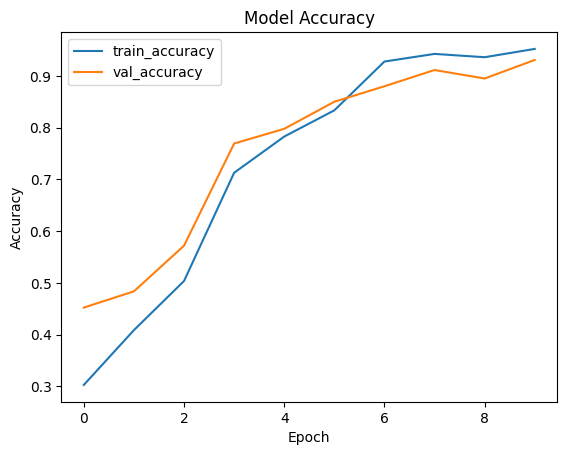

In [19]:
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

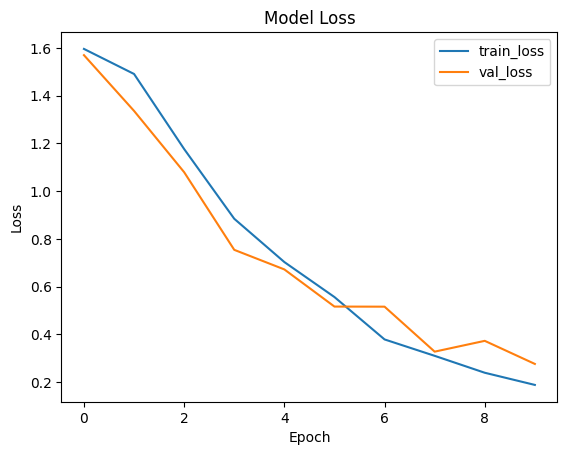

In [20]:
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [21]:
y_pred = model.predict(data_test).argmax(axis=1)

21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step


In [22]:
print(classification_report(df_test['targets'], y_pred))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91       165
           1       0.96      0.93      0.94       118
           2       0.93      0.93      0.93       120
           3       0.93      1.00      0.97       140
           4       0.94      0.89      0.91       125

    accuracy                           0.93       668
   macro avg       0.93      0.93      0.93       668
weighted avg       0.93      0.93      0.93       668



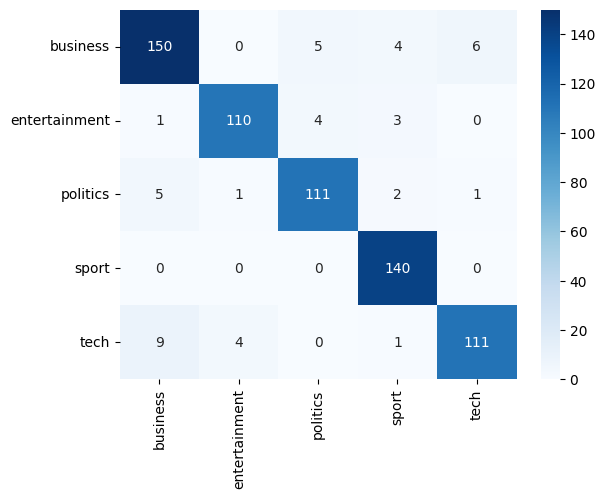

In [23]:
cm = confusion_matrix(df_test['targets'], y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=df['labels'].unique(), yticklabels=df['labels'].unique())
plt.show()